# 09 · Real-world transfer: VisDrone2019-DET (+ optional disaster imagery)


**Owner:** member B or C · **GPU:** ≈ 2.5–4 h · **Needs:** `final_model` (notebook 08)

**Dataset choice (checked Oct 2026).** No openly licensed *flood* UAV dataset with bounding boxes for MAVREC-like classes was found:
FloodNet provides classification/segmentation/VQA labels, not boxes; the "Nepal flood" imagery has no public box annotations; Roboflow
flood sets have unclear provenance and licensing. The defensible primary choice is **VisDrone2019-DET** (real UAV footage from 14
Chinese cities, 10 classes overlapping MAVREC: pedestrian/people→person, car, van, truck, bus, bicycle; academic-research license;
6,471 train / 548 val images, downloaded and converted automatically by Ultralytics' official script). It is also exactly the "other
geography" case the MAVREC paper discusses (Table 3).

Experiments (same model family as the final MAVREC model, full-frame at `best_res`):
1. **Zero-shot:** final MAVREC model on VisDrone val, scored on the 6 shared classes (Essential, no training).
2. **Fine-tune from COCO** on 1000 VisDrone images (Essential).
3. **Fine-tune from the MAVREC model** on the same 1000 images (Essential) → does MAVREC training transfer better than generic COCO?
4. Same pair with 250 images (Important: transfer benefits are usually largest in the low-data regime).

Optional disaster demo: drop any UAV flood/disaster photos in `MAVREC/real_world/flood_images/` for a qualitative figure; or place the
**C2A** dataset (synthetic humans on AIDER disaster backgrounds incl. floods, CC BY 4.0 per the authors; Kaggle `rgbnihal/c2a-dataset`)
in YOLO format under `MAVREC/real_world/C2A/` to run a quantitative person-detection fine-tune. State clearly that C2A is synthetic.

In [1]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6


In [2]:
FINAL_ID = ml.get_decision("final_model", required=True)
BEST_RES = ml.get_decision("best_res", required=True)
frec = ml.load_record(FINAL_ID)
FINAL_MODEL = frec["model_version"]
# Transfer uses a full-frame checkpoint; if the final model is tile-trained, the full-frame "D/LOO" variant is used for fine-tuning.
if frec["tiling"] == "tile_train":
    alt = [r for r in ml.results_df().itertuples() if r.model_version == FINAL_MODEL and r.tiling == "none" and r.stage in ("S6", "S3") and r.dataset_size == N_LARGE]
    INIT_ID = sorted({a.experiment_id for a in alt}, key=lambda e: ("S6" not in e, e))[0]
else:
    INIT_ID = FINAL_ID
print("final:", FINAL_ID, "| init for transfer:", INIT_ID)

final: S3_yolov8m_n2000_r1280_full_COCO_s42 | init for transfer: S3_yolov8m_n2000_r1280_full_COCO_s42


## 1 · Download + register VisDrone (≈ 2.3 GB, ~5–10 min, once per session)

In [3]:
vd = ml.prepare_visdrone()
VD = ml.register_yolo_dataset("visdrone", vd["train"], vd["val"], vd["names"], train_sizes=(250, 1000))
VD


WARNING ⚠️ Dataset 'VisDrone.yaml' images not found, missing path '/content/datasets/VisDrone/images/val'
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-val.zip to /content/datasets/VisDrone/VisDrone2019-DET-val...: 100% ━━━━━━━━━━━━ 1099/1099 983.5files/s 1.1s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-test-dev.zip to /content/datasets/VisDrone/VisDrone2019-DET-test-dev...: 100% ━━━━━━━━━━━━ 3223/3223 687.7files/s 4.7s
Unzipping /content/datasets/VisDrone/VisDrone2019-DET-train.zip to /content/datasets/VisDrone/VisDrone2019-DET-train...: 100% ━━━━━━━━━━━━ 12945/12945 1.4Kfiles/s 9.0s
Converting train: ━━━━━━━━━━━━ 6471 2.3Kit/s 2.9s
Converting val: ━━━━━━━━━━━━ 548 1.4Kit/s 0.3s
Converting test: ━━━━━━━━━━━━ 1610 2.2Kit/s 0.7s
Dataset download success ✅ (39.4s), saved to /content/datasets

visdrone: train pool 6471 imgs; val 548 imgs / 38759 boxes


{'train': {250: 'ext/visdrone_train_250', 1000: 'ext/visdrone_train_1000'},
 'val': 'ext/visdrone_val',
 'pack': 'ext_visdrone',
 'class_names': ['pedestrian',
  'people',
  'bicycle',
  'car',
  'van',
  'truck',
  'tricycle',
  'awning-tricycle',
  'bus',
  'motor']}

## 2 · Zero-shot: MAVREC model on VisDrone (shared classes only)

In [4]:
gt_mav, shared = ml.remap_gt_to_mavrec(VD["val"], ml.VISDRONE_TO_MAVREC, "visdrone_val_mavrec_space")
print("shared MAVREC classes:", [ml.CLASS_NAMES[i - 1] for i in shared])
for eid in [FINAL_ID] + ([INIT_ID] if INIT_ID != FINAL_ID else []):
    ml.evaluate(eid, split="visdrone_zeroshot", gt_name=gt_mav, eval_pack=VD["pack"], cat_ids=shared,
                mode=ml.get_decision("final_mode", "full") if eid == FINAL_ID else "full")

shared MAVREC classes: ['bicycle', 'van', 'truck', 'bus', 'person', 'car']
[S3_yolov8m_n2000_r1280_full_COCO_s42] visdrone_zeroshot|full|r1280 already evaluated


## 3 · Fine-tuning: COCO init vs MAVREC init

In [ ]:
RUN_LOW_DATA = True
sizes = [1000] + ([250] if RUN_LOW_DATA else [])
for n in sizes:
    for init, pre in [("coco", "COCO"), (f"exp:{INIT_ID}", "COCO>MAVREC")]:
        spec = ml.make_spec(FINAL_MODEL, VD["train"][n], BEST_RES, stage="S9", init=init, pretraining=pre,
                            val_set=VD["val"], test_set=VD["val"], train_pack=VD["pack"], eval_pack=VD["pack"],
                            class_names=VD["class_names"], dataset_size=n)
        ml.run_experiment(spec)

[S9_yolov8m_visdrone-train-1000_r1280_full_COCO_s42] done — skipping (force=True to redo)
[S9_yolov8m_visdrone-train-1000_r1280_full_COCO2MAVREC_s42] done — skipping (force=True to redo)
[S9_yolov8m_visdrone-train-250_r1280_full_COCO_s42] training yolov8m | data=visdrone_train_250 | res=1280 | epochs=40 | batch=4 | init=coco
Resuming from /content/drive/MyDrive/MAVREC/Final_Project_Results/runs/S9_yolov8m_visdrone-train-250_r1280_full_COCO_s42/train/weights/last.pt
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mavr

,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h,eval_split
35,S9_yolov8m_visdrone-train-250_r1280_full_COCO_s42,S9,yolov8m,250,1280.0,none,full,COCO,21.711,36.727,14.001,7.386,31.863,54.302,61.046,24.07,0.15,25.86,0.195,val
34,S9_yolov8m_visdrone-train-250_r1280_full_COCO2...,S9,yolov8m,250,1280.0,none,full,COCO>MAVREC,18.606,32.688,11.888,6.726,27.896,52.989,58.986,23.85,0.15,25.86,0.408,val
33,S9_yolov8m_visdrone-train-1000_r1280_full_COCO...,S9,yolov8m,1000,1280.0,none,full,COCO,28.060,46.089,19.518,10.638,39.424,60.616,66.814,24.27,0.15,25.86,0.674,val
32,S9_yolov8m_visdrone-train-1000_r1280_full_COCO...,S9,yolov8m,1000,1280.0,none,full,COCO>MAVREC,26.384,43.838,18.304,10.022,37.361,59.741,65.737,25.07,0.15,25.86,1.361,val
22,S3_yolov8m_n2000_r1280_full_COCO_s42,S3,yolov8m,2000,1280.0,none,full,COCO,6.009,12.223,3.971,2.094,8.874,32.376,37.735,24.81,0.12,25.86,0.739,visdrone_zeroshot


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/S9_real_world_visdrone.csv


APS             mAP50_95            
pretraining     COCO COCO>MAVREC     COCO COCO>MAVREC
dataset_size                                         
250           14.001      11.888   21.711      18.606
1000          19.518      18.304   28.060      26.384

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/S9_visdrone_transfer.png


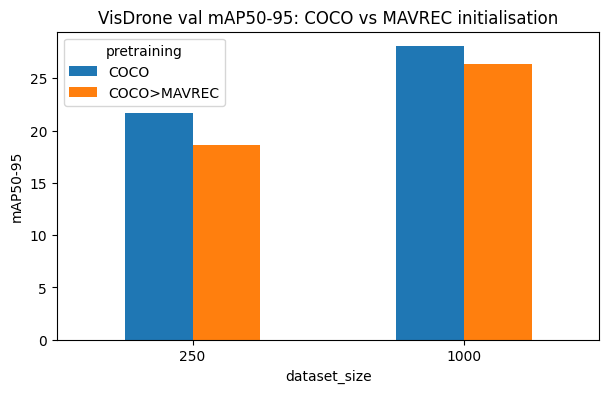

In [ ]:
df = ml.results_df()
RW = df[(df.stage == "S9") | (df.eval_split == "visdrone_zeroshot")]
display(RW[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["eval_split"]].sort_values(["eval_split", "dataset_size", "pretraining"]))
ml.save_table(RW[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"] + ["eval_split"]], "S9_real_world_visdrone")
ft = RW[RW.stage == "S9"].pivot_table(index="dataset_size", columns="pretraining", values=["mAP50_95", "APS"])
display(ft)
ft["mAP50_95"].plot.bar(rot=0, figsize=(7, 4)); plt.title("VisDrone val mAP50-95: COCO vs MAVREC initialisation"); plt.ylabel("mAP50-95")
ml.savefig("S9_visdrone_transfer.png"); plt.show()

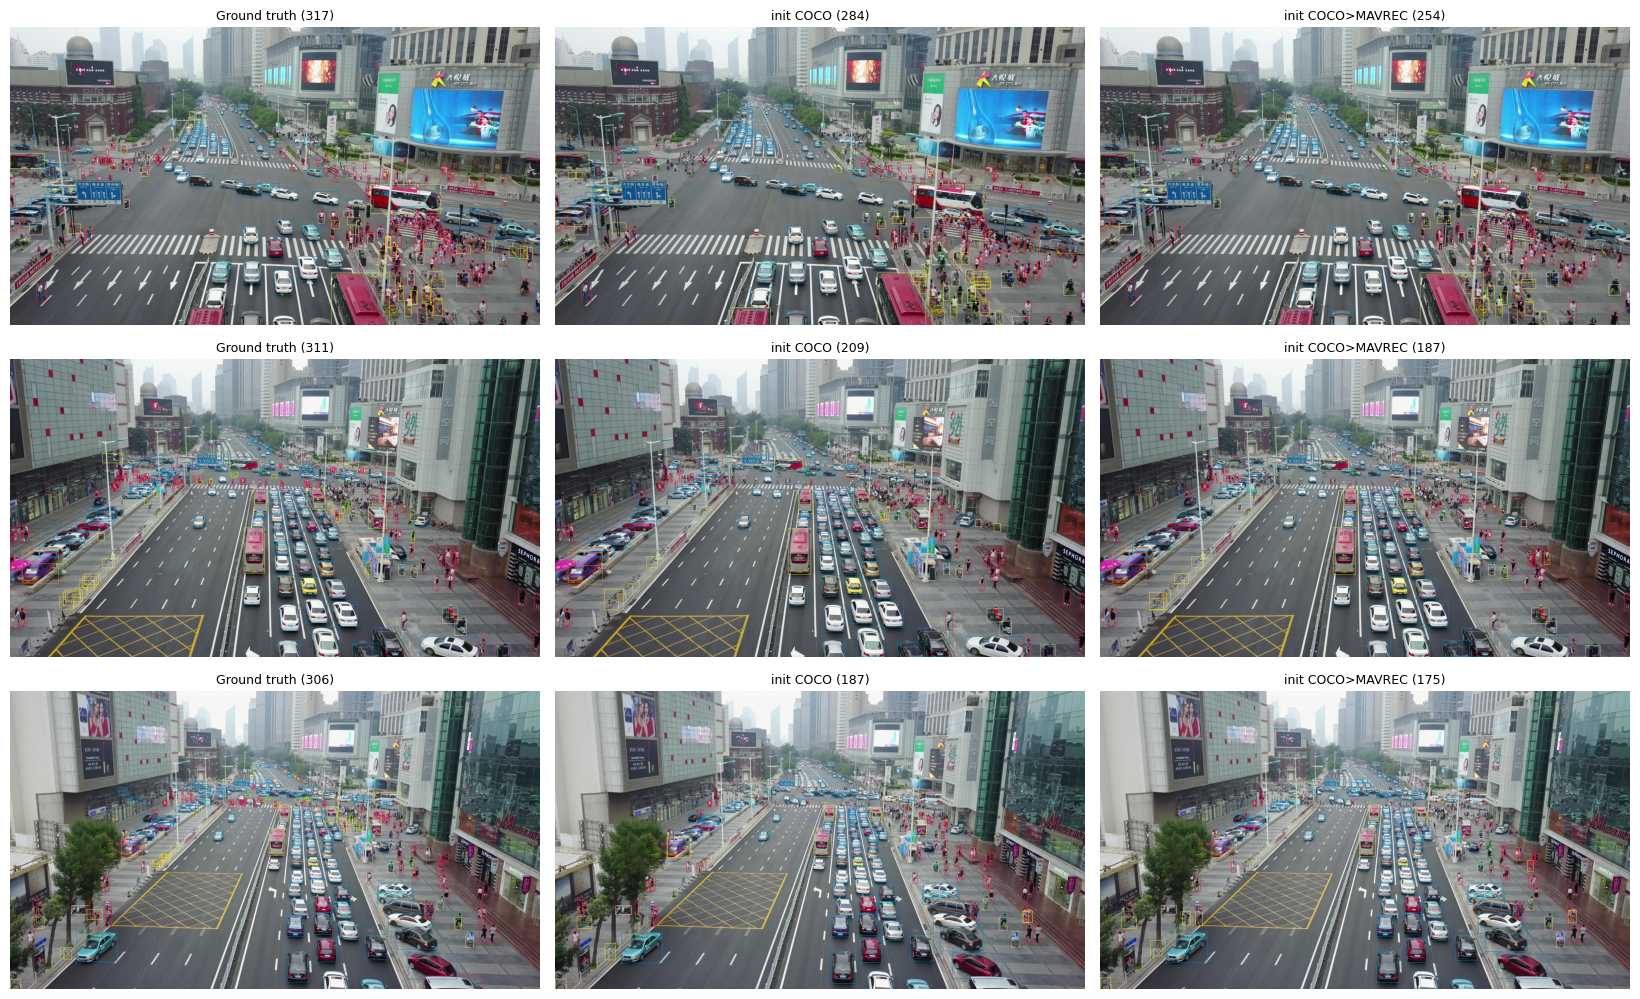

In [ ]:
ft_ids = RW[(RW.stage == "S9") & (RW.dataset_size == 1000)].sort_values("pretraining")
if len(ft_ids) == 2:
    items = [(f"init {r.pretraining}", r.preds_path, r.conf_at_best_f1) for r in ft_ids.itertuples()]
    ml.prediction_grid(items, VD["val"], VD["pack"], n=3, out_path=os.path.join(CFG["figures_dir"], "S9_visdrone_qualitative.png"))

## 4 · Optional: disaster imagery

In [ ]:
FLOOD_DIR = os.path.join(DRIVE_ROOT, "real_world", "flood_images")
if os.path.exists(FLOOD_DIR):
    ml.predict_folder(FINAL_ID, FLOOD_DIR, res=BEST_RES, conf=0.3, mode="full" if frec["tiling"] == "none" else "sliced")
else:
    print("No flood images found at", FLOOD_DIR, "— skipped (qualitative demo only).")

C2A_DIR = os.path.join(DRIVE_ROOT, "real_world", "C2A")   # expects C2A/images/{train,val} + C2A/labels/{train,val}
RUN_C2A = False
if RUN_C2A and os.path.exists(C2A_DIR):
    C2A = ml.register_yolo_dataset("c2a", os.path.join(C2A_DIR, "images", "train"), os.path.join(C2A_DIR, "images", "val"), ["human"], train_sizes=(1000,), val_max=1000)
    for init, pre in [("coco", "COCO"), (f"exp:{INIT_ID}", "COCO>MAVREC")]:
        ml.run_experiment(ml.make_spec(FINAL_MODEL, C2A["train"][1000], BEST_RES, stage="S9", init=init, pretraining=pre, val_set=C2A["val"],
                                       test_set=C2A["val"], train_pack=C2A["pack"], eval_pack=C2A["pack"], class_names=["human"], dataset_size=1000,
                                       notes="C2A synthetic disaster (person only)"))

No flood images found at /content/drive/MyDrive/MAVREC/real_world/flood_images — skipped (qualitative demo only).
